In [3]:
import sys; sys.path.append("..")
from src.data.loader import load_h2
import pandas as pd


df = load_h2()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 79330 entries, 0 to 79329
Data columns (total 31 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   IsCanceled                   79330 non-null  int64  
 1   LeadTime                     79330 non-null  int64  
 2   ArrivalDateYear              79330 non-null  int64  
 3   ArrivalDateMonth             79330 non-null  str    
 4   ArrivalDateWeekNumber        79330 non-null  int64  
 5   ArrivalDateDayOfMonth        79330 non-null  int64  
 6   StaysInWeekendNights         79330 non-null  int64  
 7   StaysInWeekNights            79330 non-null  int64  
 8   Adults                       79330 non-null  int64  
 9   Children                     79326 non-null  float64
 10  Babies                       79330 non-null  int64  
 11  Meal                         79330 non-null  str    
 12  Country                      79306 non-null  str    
 13  MarketSegment              

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from pathlib import Path

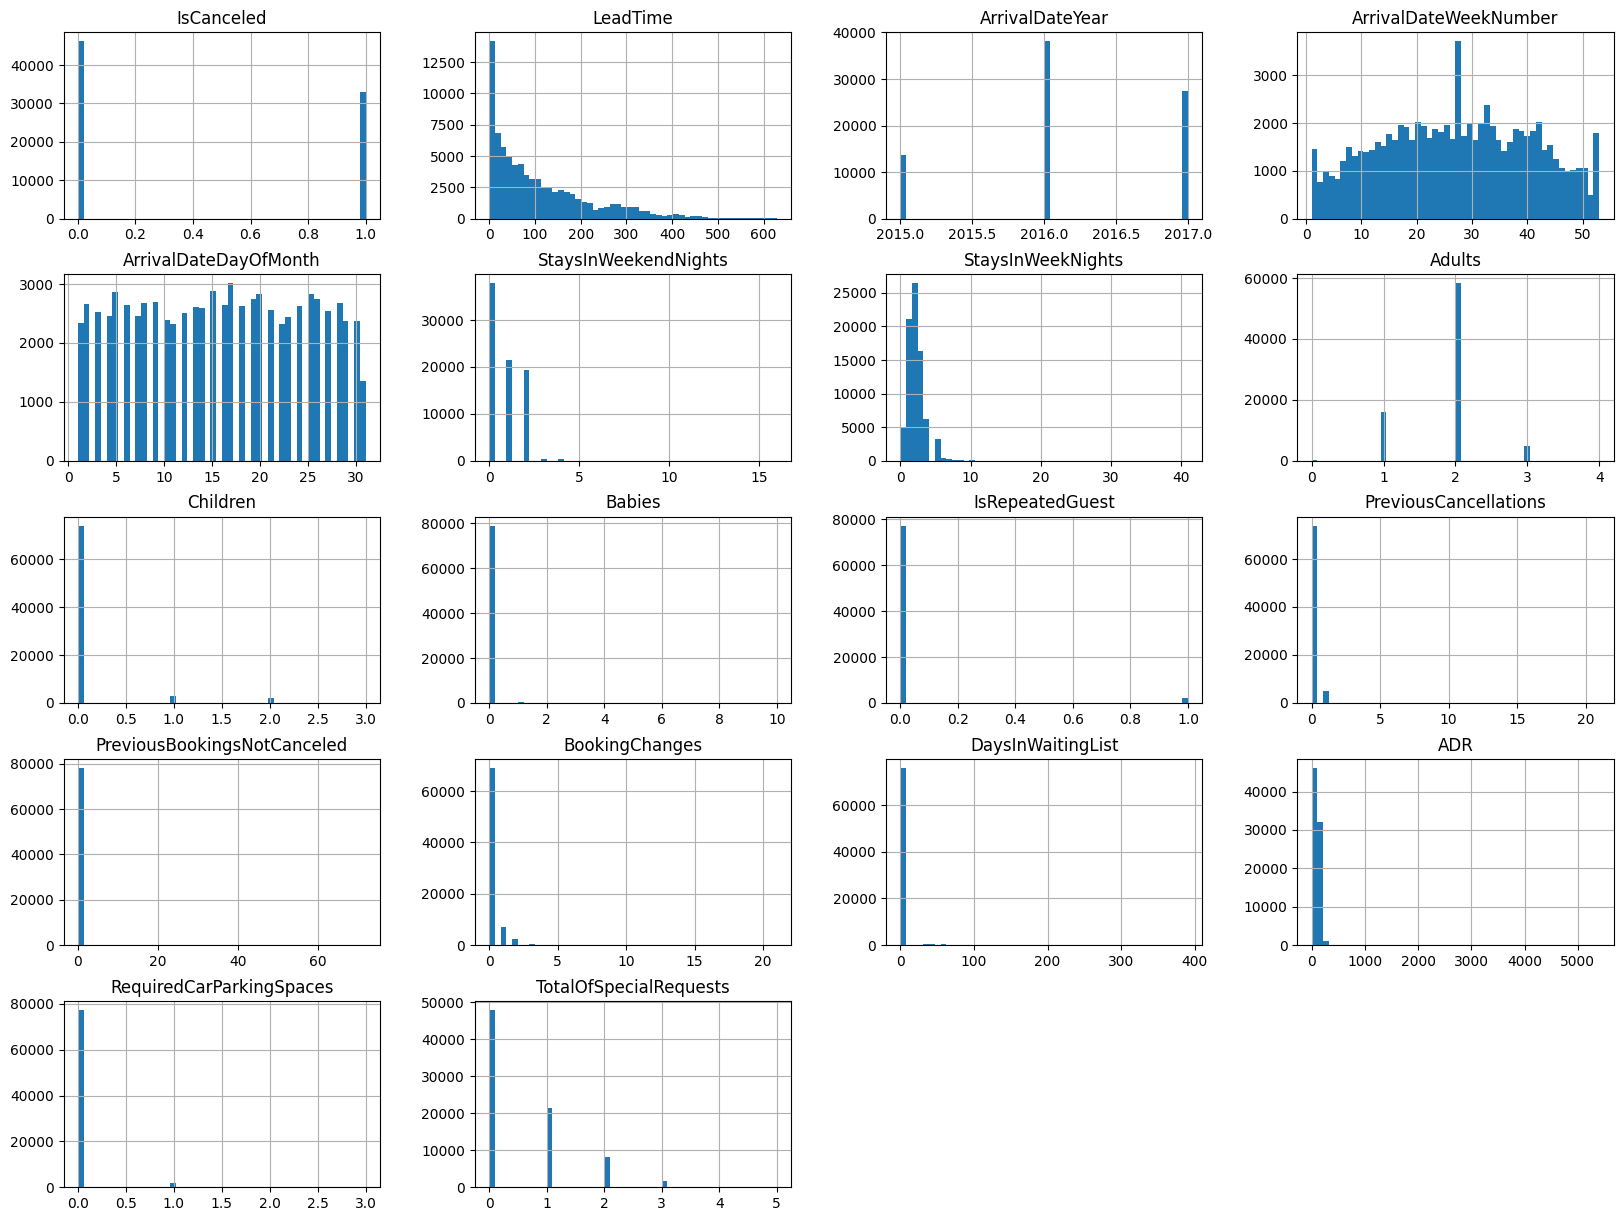

In [5]:

df.hist(bins=50, figsize=(20,15))
plt.show()

In [6]:

# 0) Load the raw file (keep_default_na=False so "NA" (Namibia) is not turned into a missing value)

print("Rows loaded:", len(df))                  # expect 79330

# 1) Strip padding spaces from every text column.
#    Do this FIRST, otherwise "   9" and "9" look different and some duplicates are missed.
text_cols = df.select_dtypes(include="str").columns
df[text_cols] = df[text_cols].apply(lambda s: s.str.strip())

# 2) Count duplicates before removing anything.
#    duplicated() marks every repeated row (after its first appearance) as True.
print("Duplicates:", df.duplicated().sum())

# 3) Remove them, keeping one copy of each row.
df = df.drop_duplicates(keep="first")

# 4) Reset the row numbers so the index runs 0, 1, 2, ... again.
df = df.reset_index(drop=True)

# 5) Check the result.
print("Rows after:", len(df))
print("Duplicates left:", df.duplicated().sum())   # must be 0 

Rows loaded: 79330
Duplicates: 25902
Rows after: 53428
Duplicates left: 0


In [7]:
df.isna().sum()

IsCanceled                     0
LeadTime                       0
ArrivalDateYear                0
ArrivalDateMonth               0
ArrivalDateWeekNumber          0
ArrivalDateDayOfMonth          0
StaysInWeekendNights           0
StaysInWeekNights              0
Adults                         0
Children                       4
Babies                         0
Meal                           0
Country                        6
MarketSegment                  0
DistributionChannel            0
IsRepeatedGuest                0
PreviousCancellations          0
PreviousBookingsNotCanceled    0
ReservedRoomType               0
AssignedRoomType               0
BookingChanges                 0
DepositType                    0
Agent                          0
Company                        0
DaysInWaitingList              0
CustomerType                   0
ADR                            0
RequiredCarParkingSpaces       0
TotalOfSpecialRequests         0
ReservationStatus              0
Reservatio

In [8]:
df[["Agent", "Company"]].describe()


,Agent,Company
count,53428,53428
unique,224,208
top,9,NULL
freq,28753,50646


3malt binary encoding for company 3shan feha nulls kter 

In [9]:
df["has_company"] = (df["Company"].str.strip() != "NULL").astype(int)
print(df["has_company"].value_counts())

has_company
0    50646
1     2782
Name: count, dtype: int64


In [10]:
df = df.drop(columns=["Company"])
print(df.shape)   

(53428, 31)


In [11]:

counts = df["Agent"].value_counts()
print(counts.head(10))


print(counts.head(10).sum() / len(df))


print((counts / len(df) < 0.01).sum())

Agent
9       28753
NULL     5587
14       3349
7        3300
28       1502
1        1226
8        1118
83        614
6         540
85        524
Name: count, dtype: int64
0.8705734820693269
215


In [12]:


# Take only the Agent column.
# Double brackets [[ ]] keep it as a table (the encoder needs a table, not a list).
# .astype(str) makes everything text, so "NULL" and IDs like 9, 14 are treated the same way.
agent = df[["Agent"]].astype(str)

# Create the encoder (this only sets the options, it doesn't touch the data yet).
agent_encoder = OneHotEncoder(
    min_frequency=0.01,                    # agents with under 1% of rows are merged into ONE "infrequent" column
    handle_unknown="infrequent_if_exist",  # a new unseen agent later is counted as "infrequent", not an error
    sparse_output=False,                   # return a normal table of numbers, easier to read
)

# fit  = learn which agents are common and which are rare
# transform = turn each row into 0/1 columns
# Here it runs on all of df ONLY to look at it. The real fit uses the training set (Part 2).
agent_encoded = agent_encoder.fit_transform(agent)

print(agent_encoded.shape)                    # (rows, columns): expect about (79330, 13)
print(agent_encoder.get_feature_names_out())  # names of the new columns, e.g. Agent_9, Agent_NULL

(53428, 10)
['Agent_1' 'Agent_14' 'Agent_28' 'Agent_6' 'Agent_7' 'Agent_8' 'Agent_83'
 'Agent_9' 'Agent_NULL' 'Agent_infrequent_sklearn']


to do
i still need to work one the encoder for agent

In [13]:
# bookings with nobody staying
print(((df["Adults"] + df["Children"].fillna(0) + df["Babies"]) == 0).sum())
# bookings with zero nights
print(((df["StaysInWeekendNights"] + df["StaysInWeekNights"]) == 0).sum())

154
288


In [14]:
# Total guests per booking (missing Children counted as 0 for this check only)
guests = df["Adults"] + df["Children"].fillna(0) + df["Babies"]

df = df[guests > 0].reset_index(drop=True)
print("Rows after:", len(df))

Rows after: 53274


before drop the zero nights rows i need to check if the check out done or not

In [15]:
zero_nights = (df["StaysInWeekendNights"] + df["StaysInWeekNights"]) == 0

# What share of these bookings were canceled? (overall rate is about 0.42)
print(df[zero_nights]["IsCanceled"].mean())

# What do their reservation statuses look like?
print(df[zero_nights]["ReservationStatus"].value_counts())

0.05627705627705628
ReservationStatus
Check-Out    218
No-Show        7
Canceled       6
Name: count, dtype: int64


In [16]:
# Total nights per booking
nights = df["StaysInWeekendNights"] + df["StaysInWeekNights"]

print("Zero-night rows:", (nights == 0).sum())      # expect 231

# Keep only bookings with at least one night
df = df[nights > 0].reset_index(drop=True)
print("Rows after:", len(df))                         # expect 53274 - 231 = 53043

Zero-night rows: 231
Rows after: 53043


In [17]:
df["ADR"].describe()
print((df["ADR"] <= 0).sum())

722


In [18]:
print(df["ADR"].describe())                              # min, max, mean, quartiles

zero_adr = df["ADR"] <= 0
print("ADR <= 0 rows:", zero_adr.sum())
print("Cancellation rate:", df[zero_adr]["IsCanceled"].mean())    # overall is about 0.42
print(df[zero_adr]["MarketSegment"].value_counts())               # who are these bookings?
print("Negative ADR:", (df["ADR"] < 0).sum())                     # truly negative values

count    53043.000000
mean       111.756553
std         47.336946
min          0.000000
25%         85.000000
50%        105.740000
75%        134.100000
max       5400.000000
Name: ADR, dtype: float64
ADR <= 0 rows: 722
Cancellation rate: 0.1149584487534626
MarketSegment
Complementary    459
Groups           103
Offline TA/TO     96
Direct            35
Online TA         23
Corporate          6
Name: count, dtype: int64
Negative ADR: 0


In [19]:
print(df["ADR"].nlargest(10))          # the 10 most expensive bookings
print((df["ADR"] > 500).sum())         # how many are above 500
print((df["ADR"] > 1000).sum())        # how many are above 1000

4751     5400.00
46400     510.00
40206     451.50
40110     375.50
52351     372.33
31826     365.00
18112     352.50
40095     349.63
34588     345.00
49771     338.00
Name: ADR, dtype: float64
2
1


In [20]:
# One booking has ADR = 5400, more than 10 times the next highest value (510).
# It is almost certainly an entry error, so we remove it for ALL tasks.
# We use a limit (1000) instead of "== 5400" so the rule is readable and justified.
ADR_MAX = 1000

print("Rows before:", len(df))                  # expect 53043
print("ADR above limit:", (df["ADR"] > ADR_MAX).sum())   # expect 1

df = df[df["ADR"] <= ADR_MAX].reset_index(drop=True)

print("Rows after:", len(df))                   # expect 53042
print("New max ADR:", df["ADR"].max())          # expect 510.0

Rows before: 53043
ADR above limit: 1
Rows after: 53042
New max ADR: 510.0


In [21]:
print(df.duplicated().sum())
print(df.groupby("ReservationStatus")["IsCanceled"].mean())

0
ReservationStatus
Canceled     1.0
Check-Out    0.0
No-Show      1.0
Name: IsCanceled, dtype: float64


In [22]:
#BABIES_MAX = 2   # more than 2 babies in one booking is not plausible

#print("Rows with too many babies:", (df["Babies"] > BABIES_MAX).sum())
#df = df[df["Babies"] <= BABIES_MAX].reset_index(drop=True)
#print("Rows after:", len(df))

In [23]:
# Total guests per booking (missing Children counted as 0 for this check only)
guests = df["Adults"] + df["Children"].fillna(0) + df["Babies"]

df = df[guests > 0].reset_index(drop=True)
print("Rows after:", len(df))

Rows after: 53042


In [24]:
print(df["Babies"].value_counts().sort_index())

Babies
0     52676
1       358
2         6
9         1
10        1
Name: count, dtype: int64


# More than 2 babies in one booking is not plausible, so we remove those rows.
BABIES_MAX = 2

In [25]:
# Babies: values go 0, 1, 2 and then jump to 9 and 10.
# More than 2 babies in one booking is not plausible, so we remove those rows.
BABIES_MAX = 2

print("Rows before:", len(df))                           # expect 53042
print("Too many babies:", (df["Babies"] > BABIES_MAX).sum())   # expect 2

df = df[df["Babies"] <= BABIES_MAX].reset_index(drop=True)

print("Rows after:", len(df))                            # expect 53040

Rows before: 53042
Too many babies: 2
Rows after: 53040


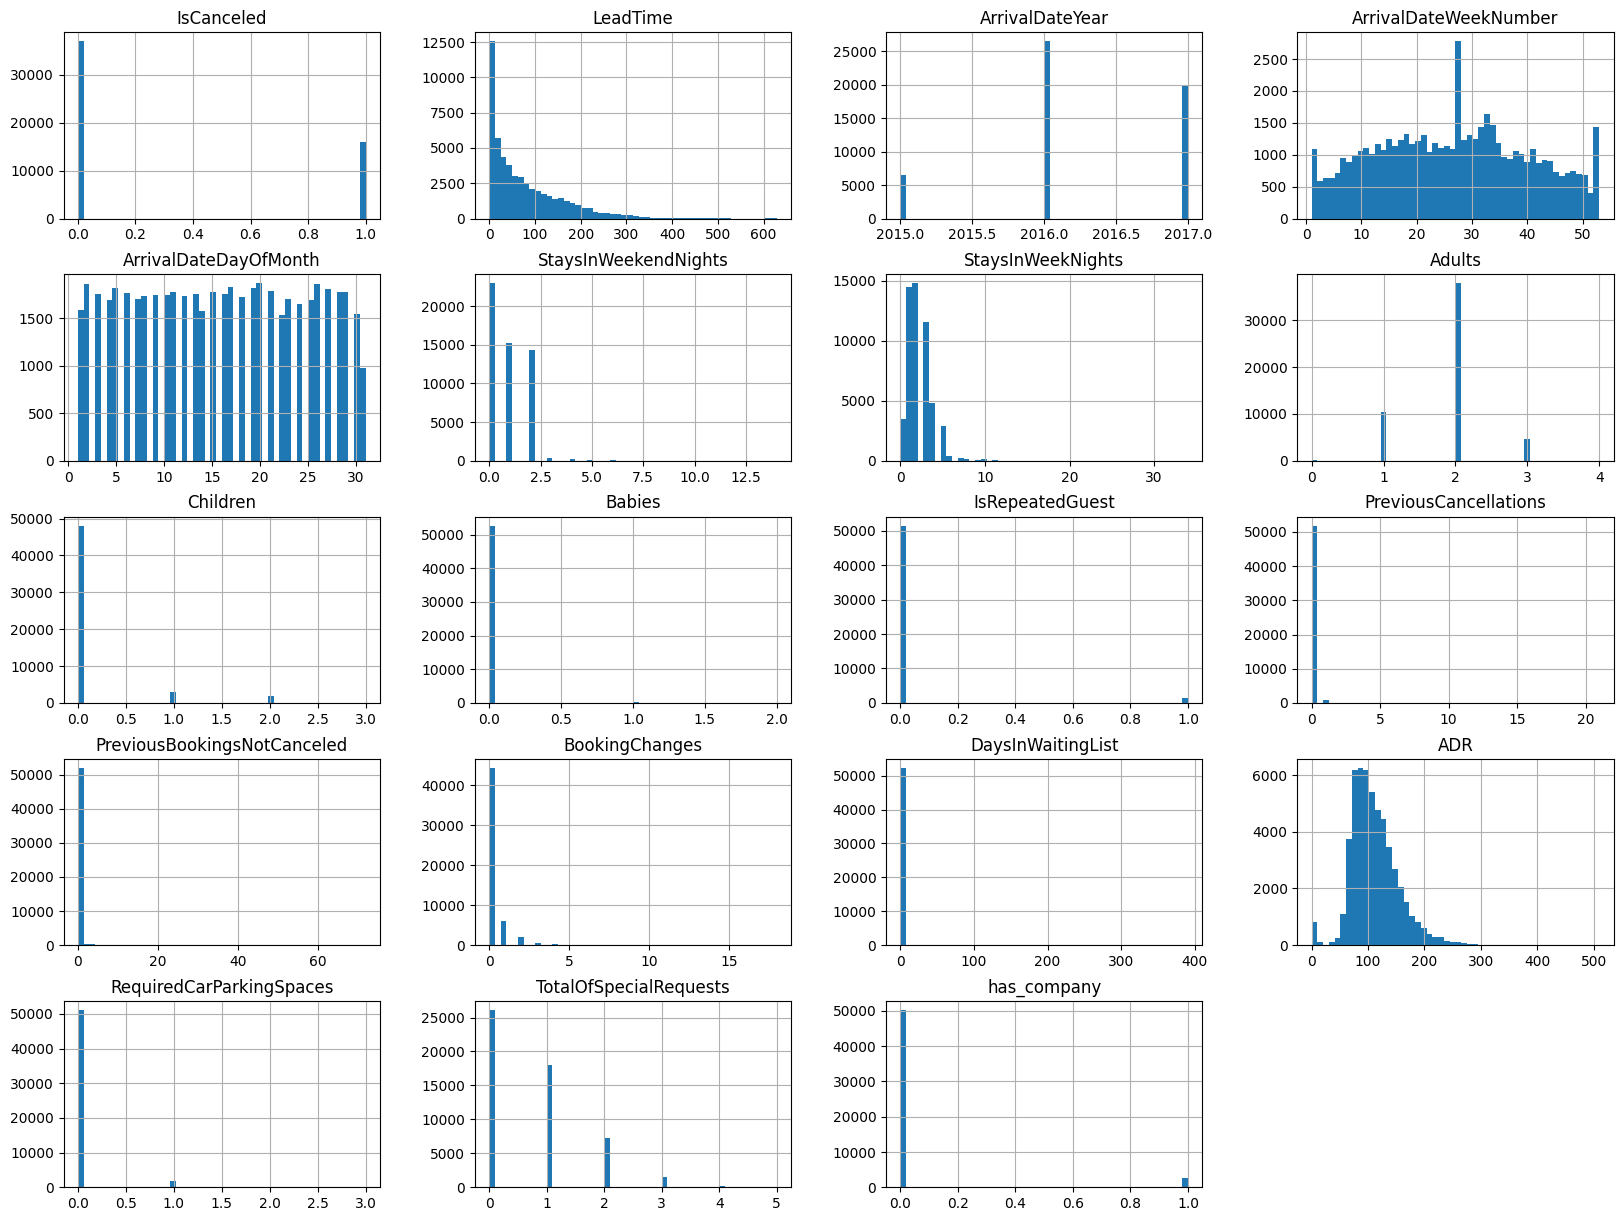

In [26]:
df.hist(bins=50, figsize=(20,15))
plt.show()

In [27]:
print((df["Adults"] == 0).sum())
no_adult = df["Adults"] == 0

print(df[no_adult][["Children", "Babies"]].value_counts())   # how many kids/babies in these bookings
print(df[no_adult]["IsCanceled"].mean())                      # compare with the overall rate (about 0.30)
print(df[no_adult]["MarketSegment"].value_counts())           # who books like this?

219
Children  Babies
2.0       0         201
3.0       0          11
1.0       0           4
2.0       1           3
Name: count, dtype: int64
0.3698630136986301
MarketSegment
Online TA        183
Direct            29
Complementary      4
Offline TA/TO      3
Name: count, dtype: int64


In [28]:
no_adult = df["Adults"] == 0
print(df[no_adult]["ADR"].describe())
print(df[~no_adult]["ADR"].describe())

count    219.000000
mean      80.923973
std       36.565326
min        0.000000
25%       73.565000
50%       87.080000
75%      104.150000
max      155.680000
Name: ADR, dtype: float64
count    52821.000000
mean       111.785106
std         41.367560
min          0.000000
25%         85.000000
50%        106.000000
75%        134.300000
max        510.000000
Name: ADR, dtype: float64


In [29]:


SEED = 42   # fixed seed so everyone gets the identical split

# Step 1: split off the TEST set (15%). Stratify on IsCanceled so the
# cancellation rate is the same in every set. Nobody looks at it until the end.
train_val, test = train_test_split(
    df, test_size=0.15, random_state=SEED, stratify=df["IsCanceled"])

# Step 2: split the rest into TRAIN and VALIDATION.
# We need 15% of the original data, which is 15/85 of what is left.
train, val = train_test_split(
    train_val, test_size=0.15 / 0.85, random_state=SEED,
    stratify=train_val["IsCanceled"])

# Checks
print("Rows:", len(train), len(val), len(test))   # about 37128, 7956, 7956
print("Total:", len(train) + len(val) + len(test)) # must be 53040

# Cancellation rate should be nearly the same in all three
for name, part in [("train", train), ("val", val), ("test", test)]:
    print(name, round(part["IsCanceled"].mean(), 4))

# No row should appear in two sets
print("Overlap:", len(set(train.index) & set(val.index)),
      len(set(train.index) & set(test.index)),
      len(set(val.index) & set(test.index)))   # must be 0 0 0

Rows: 37127 7957 7956
Total: 53040
train 0.3021
val 0.302
test 0.302
Overlap: 0 0 0


In [30]:

out = Path("..") / "data" / "processed"
out.mkdir(parents=True, exist_ok=True)

train.to_csv(out / "train.csv", index=False)
val.to_csv(out / "val.csv", index=False)
test.to_csv(out / "test.csv", index=False)